# Lesson 7 · Everything is made of sines — stack up sine waves by hand to build a square wave, and push open the door to Fourier

**Learning goals**
1. Build the intuition: a complex waveform = a sum of sines; and you can also take it apart into its sine components
2. Implement `square_approx(t, n)`: approximate a square wave with odd harmonics
3. Be able to explain "why only odd harmonics" (half-wave symmetry)
4. Know the Gibbs phenomenon: at a jump the sum overshoots, and adding more terms doesn't remove it — it only makes it narrower

**Why it matters for Aurora**: the FFT and STFT in `aurora.audio.transforms` do exactly this decomposition — they turn a sampled signal back into the amplitude and phase of each frequency.
The **spectrogram** you saw in L03: from now on, you can think of each of its columns as "one round of this kind of Fourier analysis on a short slice of sound". Stitching the short slices together properly is the STFT (L43); in this lesson we first nail down the intuition of "adding it back up / pulling it apart".

← **Previous lesson** · [L06 · Euler's formula e^{iθ}=cosθ+isinθ](L06_euler.en.ipynb)

> Last lesson covered **Euler's formula e^{iθ}=cosθ+isinθ**: the twiddle factor is the lifeblood of the FFT.
> This lesson explores **everything is made of sines**.

## This lesson's story: pulling apart the voices of a choir

Imagine a choir singing. Close your eyes: you can pick out the tenors, the altos, the deep basses... Each section sings a different "pitch", yet your ears can separate them one by one.

That's not magic — it's the **superposition principle**: a complex waveform = several sine waves added together.

And the other way around: **any periodic waveform can be approximated by a weighted sum of sine waves**. That is the core intuition of Fourier analysis.

In this lesson we start with the simplest example: stacking odd harmonics to build a **square wave**.
The more terms you add, the steeper the edges and the flatter the top of the combined waveform — gradually "pressing out" the shape of a square wave.

> This is the FFT run in reverse: the FFT breaks a complex waveform into a pile of sine waves; here we put the sine waves back together, to get a feel for the process.

## 2-minute warm-up: square wave = a stack of harmonics

- The sharper the square wave's jumps, the more high-frequency components you need in the frequency domain to approximate it
- Keep only the odd harmonics, and you already capture the square wave's upper and lower plateaus
- The more terms, the steeper the edges — and near each jump there's a little "overshoot" ringing (its official name is the Gibbs phenomenon; we'll name it properly in §1)

For this lesson, lock in one intuition first: a complex waveform = a sum of sines.

## 1. Add a few sines → a complex waveform

Why build a square wave out of sines? Because the math tells us:

```
square wave ≈ (4/π) · [sin(2πt)/1 + sin(6πt)/3 + sin(10πt)/5 + ...]
```

That is: use only the **odd harmonics (k = 1, 3, 5, ...)**, each with weight 4/(πk).

Three features worth remembering now — you'll check them by hand in a moment:
1. **Frequency**: the k-th harmonic has k times the fundamental frequency (f0)
2. **Weight**: the higher the frequency, the smaller the contribution (it decays as 1/k)
3. **Range of the sum**: the square wave itself takes the values ±1; a finite sum gets close to ±1 on the flat parts, but overshoots to about ±1.18 at the jumps (the Gibbs phenomenon: the overshoot is about 9% of the jump size 2; it doesn't disappear no matter how many terms you add — it only shrinks toward the jump point)

Run the code cells below and watch how the combined waveform approaches a square wave step by step as the number of harmonics grows.

### Why "odd" harmonics, of all things? — an intuition from symmetry

Don't rush to memorize the conclusion "use only odd harmonics". Let's look at an easier question first: **what special symmetry does the square-wave shape itself have?**

Take the graph of a square wave and try this experiment: shift the whole waveform right by half a period, then flip it upside down (+1 becomes -1, -1 becomes +1). You'll find that — **the result is exactly the same as the original waveform**. In one line: a square wave satisfies `f(t + T/2) = −f(t)` (where T is the period). This property is called **half-wave symmetry**.

It can be proved mathematically: **as long as a periodic signal has half-wave symmetry, the even-harmonic coefficients in its Fourier series are automatically 0** — nobody removed them by hand; they simply come out as zero. Here's an intuitive way to see it: even harmonics (k=2, 4, 6...) have a peculiar trait — shift one right by half a period and its shape is **unchanged** (`sin(2π·2·(t+T/2)) = sin(2π·2·t)`, no sign flip). If the square wave contained a component like that, the overall property "shift by half a period, flip the sign, get exactly the same thing" would be broken — but the square wave really does have this property, so the share of even harmonics must be exactly zero to keep it intact.

Odd harmonics are the opposite: `sin(2π·k·(t+T/2)) = −sin(2π·k·t)` (when k is odd, the extra half turn flips the sign exactly) — which matches the square wave's requirement "shift by half a period and flip the sign, and nothing changes". That's why only odd harmonics can appear in the square wave's series.

If you're itching to check "what happens if I mix in an even harmonic", the code cell below makes the comparison: one set uses only odd harmonics (1, 3, 5), the other mixes in an extra even harmonic (2). See whether the second one can still keep the symmetric look a square wave should have.

In [1]:
# Aurora matplotlib bootstrap
from pathlib import Path
import sys

_root = None
_cwd = Path.cwd().resolve()
for _candidate in (_cwd, *_cwd.parents):
    if (_candidate / '_matplotlib_bootstrap.py').exists():
        _root = _candidate
        break
if _root is None:
    _notebooks_dir = _cwd / 'notebooks'
    if _notebooks_dir.exists():
        for _found in _notebooks_dir.rglob('_matplotlib_bootstrap.py'):
            _root = _found.parent
            break
if _root is not None and str(_root) not in sys.path:
    sys.path.insert(0, str(_root))

from _matplotlib_bootstrap import apply as _aurora_mpl_apply
_aurora_mpl_apply()


In [ ]:
import numpy as np, matplotlib.pyplot as plt

t = np.linspace(0, 1, 1000)

# Odd harmonics only: k=1,3,5
odd_only = sum((4/(np.pi*k)) * np.sin(2*np.pi*k*t) for k in [1, 3, 5])

# Odd harmonics + one even harmonic k=2 mixed in (any nonzero amplitude will do, e.g. 4/(π*2))
odd_plus_even = odd_only + (4/(np.pi*2)) * np.sin(2*np.pi*2*t)

fig, axes = plt.subplots(1, 2, figsize=(10, 3.5), sharey=True)
axes[0].plot(t, odd_only); axes[0].set_title('odd harmonics only (k=1,3,5)\nhalf-wave symmetry kept')
axes[1].plot(t, odd_plus_even); axes[1].set_title('odd + even harmonic (k=2)\nsymmetry broken, shape skewed')
for ax in axes:
    ax.axhline(0, color=plt.rcParams["grid.color"], linewidth=0.5)
plt.tight_layout(); plt.show()

print('Compare the two plots: with an even harmonic mixed in, the first half of the wave no longer lines up with its "shift by half a period + flip" version -')
print('and that is why the even-harmonic coefficients in the Fourier series of a square wave must be exactly 0.')

## Into the lab: watch harmonics add up

Every odd harmonic you add makes the edges of the combined waveform a bit steeper and the top a bit flatter. This cell first plots a basic 2 Hz + 5 Hz sum; later cells generalize it to any number of terms.

> 📌 **Quick reminder**: the 2 Hz and 0.5·(5 Hz) in the cell below are just two frequencies picked at random, to show "what two arbitrary sine waves look like when you add them". They are **not** harmonically related (5 is not an integer multiple of 2), and there's no notion of a "fundamental" here yet. The example that really ties in with "harmonics" starts in the next section ("Hands-on observation"), where every frequency is an integer multiple of the same fundamental. Don't mix these two things up.

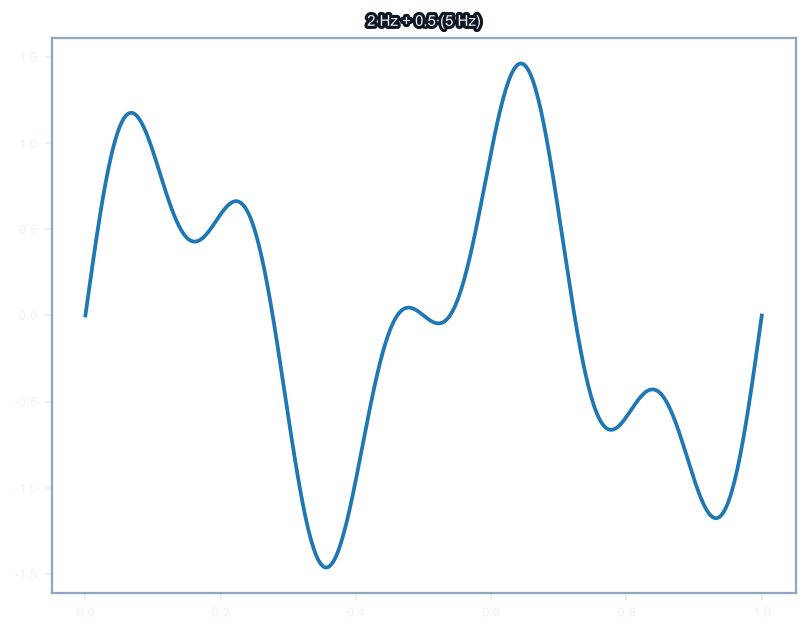

In [3]:
import numpy as np, matplotlib.pyplot as plt
t = np.linspace(0, 1, 500)
y = np.sin(2*np.pi*2*t) + 0.5*np.sin(2*np.pi*5*t)
plt.plot(t, y); plt.title('2 Hz + 0.5·(5 Hz)'); plt.show()

## Hands-on: what each component looks like

First, let's print the first few odd harmonics on their own. Notice that the k-th component has k times the fundamental frequency and weight 1/k — the higher the frequency, the smaller the contribution.

### First, what exactly is a "harmonic"? — the guitar-string analogy

Pluck a guitar string and what you hear is not a single-frequency "pure tone" but a whole "family of frequencies" stacked together:

- The whole string vibrating as one gives the lowest, loudest note, called the **fundamental frequency** (written f0) — that's the pitch you mean when you say "which note was played".
- But the string also vibrates in halves, thirds... of its length at the same time, each giving off higher frequencies 2f0, 3f0, 4f0..., just much quieter than the fundamental. These extra frequencies sit on top of the fundamental and make a guitar sound "full" and "textured", rather than thin like a tuning fork.

Mathematically, we number these frequencies like this:

| Index k | Frequency | Name |
|---|---|---|
| k=1 | 1×f0 | fundamental (1st harmonic) |
| k=2 | 2×f0 | 2nd harmonic |
| k=3 | 3×f0 | 3rd harmonic |
| k=4 | 4×f0 | 4th harmonic |

**"The k-th harmonic" is the sine component whose frequency is exactly k times the fundamental** — no more, no less; it has to be an integer multiple, which is a hard requirement of the word "harmonic" (if the frequency isn't an integer multiple, it isn't a harmonic but a separate, independent tone, like the randomly chosen 2 Hz + 5 Hz in this lesson's "Starting experiment" cell).

> ⚠️ **An easy mix-up**: in music, "overtones" are conventionally counted from **above** the fundamental, so "1st overtone" = 2nd harmonic, "2nd overtone" = 3rd harmonic... the overtone number is one less than the harmonic number. This lesson sticks to the "k-th harmonic" numbering throughout (k=1 is the fundamental itself) so you don't have to keep converting back and forth.

A concrete example: the A4 pitch commonly used to tune pianos and guitars has a fundamental f0 = 440 Hz. Then:
- 1st harmonic (fundamental): 440 Hz
- 3rd harmonic: 3 × 440 = 1320 Hz
- 5th harmonic: 5 × 440 = 2200 Hz

The code below prints, for a fundamental f0 = 1 Hz, the instantaneous value at t=0.25 s of the first few **odd** harmonics (the 1st, 3rd, 5th, 7th and 9th) — exactly the frequency components a square wave uses.

In [ ]:
import numpy as np

# Instantaneous values of the first 5 odd harmonics at t=0.25 s (fundamental 1 Hz; this table leaves out the common factor 4/π)
t = 0.25  # the 1/4 point, inside the square wave's first positive half-period
print(f"{'k':>4}  {'sin(2π×k×t)':>14}  {'weight 1/k':>10}  {'contrib.':>10}")
print('-' * 48)
for k in range(1, 10, 2):  # odd: 1,3,5,7,9
    raw = np.sin(2 * np.pi * k * t)
    weighted = raw / k
    print(f'{k:>4}  {raw:>+14.4f}  {1/k:>10.4f}  {weighted:>+10.4f}')


### In the table above, why does the sign jump between +1 and -1? — a quick look back at the unit circle

Look at the printed table: for k=1 it's +1.0000, for k=3 it's -1.0000, for k=5 it's +1.0000 again... the sign alternates regularly. That's no coincidence — it's a geometric necessity. Let's go back to the unit circle from L06 and see.

Recall: `sin(θ)` is the **y-coordinate** of the point on the unit circle you reach by starting at (1, 0) and turning counterclockwise by angle θ. At t=0.25 s, the angle the k-th harmonic has turned through is:

```
θ_k = 2π × k × 0.25 = kπ/2
```

- k=1 → θ=π/2=90°, we're at the top of the circle (0, 1), y-coordinate = **+1**
- k=3 → θ=3π/2=270°, we're at the bottom of the circle (0, -1), y-coordinate = **-1**
- k=5 → θ=5π/2=90°+one full turn, back at the top (0, 1), y-coordinate = **+1**
- k=7 → θ=7π/2=270°+one full turn, at the bottom (0, -1), y-coordinate = **-1**

Because each step turns an extra half circle (every time k goes up by 2, we turn π radians = 180° more), the landing point flips back and forth between "top" and "bottom" — that's the geometric reason for the alternating sign. Below we draw a unit circle and mark the points for these angles, so you can see it for yourself.

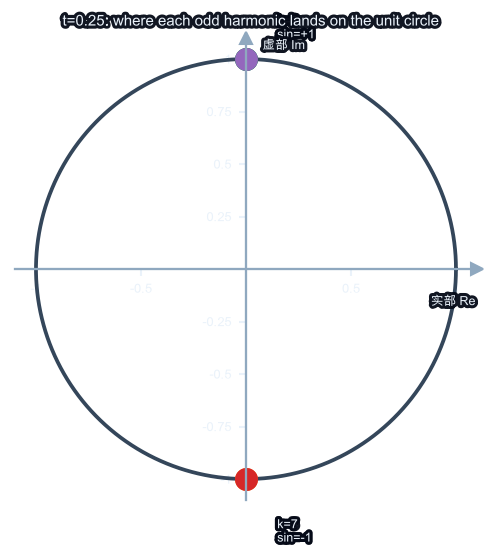

In [5]:
import numpy as np, matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(4, 4))
theta_circle = np.linspace(0, 2*np.pi, 200)
ax.plot(np.cos(theta_circle), np.sin(theta_circle), plt.rcParams["grid.color"])

t = 0.25
for k in range(1, 10, 2):
    theta = 2*np.pi*k*t  # = kπ/2
    x, y = np.cos(theta), np.sin(theta)
    ax.plot(x, y, 'o', markersize=10)
    ax.annotate(f'k={k}\nsin={y:+.0f}', (x, y),
                textcoords="offset points", xytext=(15, 10 if y > 0 else -30))

ax.axhline(0, color=plt.rcParams["text.color"], linewidth=0.5)
ax.axvline(0, color=plt.rcParams["text.color"], linewidth=0.5)
ax.set_aspect('equal')
ax.set_title('t=0.25: where each odd harmonic lands on the unit circle')
plt.show()

## Code experiment: from 1 to 9 terms

Below we add harmonics step by step from n=1 to n=9 and watch how closely the combined waveform approximates a square wave as the number of terms grows.

In [ ]:
import numpy as np

# Add odd harmonics one at a time and watch the sum converge to π/4 (t=0.25)
t = 0.25
theory = np.pi / 4  # theoretical value of the series at t=0.25
acc = 0.0
print(f"{'terms':>4}  {'added':>6}  {'new term':>12}  {'sum':>12}  {'error':>10}")
print('-' * 55)
for i, k in enumerate([1, 3, 5, 7, 9]):
    term = np.sin(2 * np.pi * k * t) / k
    acc += term
    print(f'{i+1:>4}  k={k:1d}    {term:>+12.4f}  {acc:>+12.4f}  {abs(acc-theory):>10.4f}')
print(f'\nπ/4 ≈ {theory:.4f} (closer and closer! Multiply by the common factor 4/π and you get exactly the square-wave value 1)')


### Where does this π/4 come from? — a 350-year-old "coincidence"

In the code above, `theory = np.pi/4`, and you can watch the partial sums creep toward 0.7854... That number looks like it came out of nowhere, but we have actually already derived it with our own hands — we just haven't noticed yet.

Recall the unit-circle result from the previous cell: at t=0.25, `sin(kπ/2)` for odd k goes +1, -1, +1, -1, ... (k=1,3,5,7,...). Plug that into the partial sum:

```
Σ sin(kπ/2)/k  =  1/1 − 1/3 + 1/5 − 1/7 + 1/9 − ...
```

This series — "alternating signs, denominators running through the odd numbers" — has a name of its own in history: the **Leibniz series**, proved back in the 17th century to converge to exactly:

```
1 − 1/3 + 1/5 − 1/7 + 1/9 − ... = π/4
```

In other words, it's not that we declared it equal to π/4; the act of "adding up the alternating sine values from the unit circle with 1/k weights" is mathematically proven to converge to π/4 — a deep and beautiful link between trigonometry and the number π. The full proof is beyond the scope of this course, but knowing that it is a classic result "with a name", not a fluke, should put your mind at ease.

Precisely because the true height of a square wave is ±1, while this series naturally converges to π/4, we need the factor 4/π that comes next, to "stretch" π/4 back to 1 — in the next section we'll see where that factor actually comes from.

## 2. ✏️ Approximate a square wave with a sum of odd harmonics: `square_approx(t, n)`

square wave ≈ `(4/π) · Σ_{k=1,3,5,...} sin(2π·k·t) / k` (take the first n odd harmonics, i.e. each term has weight `4/(πk)`).

**Line of reasoning**:
1. The output must be as long as `t`, so first initialize an accumulator `result` with `np.zeros_like(t)`, which makes the dtype and shape line up automatically.
2. The odd-harmonic indices are `1, 3, 5, ..., 2n-1`; generate them with `range(1, 2*n, 2)` — `n` terms in total.
3. In each pass through the loop, add `(4/(np.pi*k)) * np.sin(2*np.pi*k*t)` to `result` — the denominator `k` makes higher-frequency components weigh less, and the common factor `4/π` pulls the limit from π/4 up to the square wave's ±1.

**Reference input and output**: with `n=1` there is only the fundamental, and the output is a plain sine (peak 4/π ≈ 1.27); with `n=5` the top of the waveform already shows clear "shoulders"; with `n=50` the square wave's upper and lower plateaus are clearly visible, with Gibbs ringing only at the jumps.

> 💡 Need a hint? Once you've finished the exercise, you can compare with the reference implementation in the `solutions/` folder.


### Optional · if you want the "general recipe for coefficients": how is 4/π actually computed?

> The main path already has what you need: half-wave symmetry explains "why only odd", plus the numerical-integration table further down.
> This section is a general method for anyone who wants to know "how do I find the coefficients for a different waveform". **Skipping it won't stop you from implementing `square_approx`**.

So far we found the coefficient by "working backwards": first we noticed that without a factor the limit is π/4, then we "used 4/π to pull it back to 1". That holds up mathematically, but switch to another function — say a triangle wave or a sawtooth — and you can't count on it "happening to converge to π/4" every time. What's the truly general approach?

**Analogy**: imagine you have a glass of "mixed juice" in front of you (that's our square-wave signal), and you want to know "how much of this juice is apple, and how much is orange". If you had a magic test strip — dip it in the mixed juice and it reacts only to "apple", with zero reaction to every other flavor — you could measure the apple share exactly. That's what **orthogonality** means: sine waves of different frequencies are like "flavor test strips" that don't interfere with each other.

Mathematically, this "test strip" is an **integral**. For a signal f(t) with period T, if you want to know "how much of the k-th harmonic is in there", you compute:

```
b_k = (2/T) ∫₀ᵀ f(t) · sin(2π·k·t/T) dt
```

The principle behind it: take two sine waves of different frequencies (m≠k), `sin(2π·m·t/T)` and `sin(2π·k·t/T)`, multiply them and integrate over one period, and the result is **always 0** — just like the test strip's zero reaction to other flavors. Only when m=k (a sine multiplied by itself) is the integral nonzero, which "picks out" exactly the coefficient of that frequency. This "sifting" operation is called the Fourier coefficient formula, and `4/π` is exactly what you get by applying this integral to the square wave (for k=1).

The code cell below skips the symbolic derivation and instead checks this **directly by numerical integration**: for k=1 to 6, it computes `b_k = (2/T)∫f(t)sin(2πkt/T)dt` numerically. You'll see that odd k match `4/(πk)` exactly, while even k come out ≈ 0 — the most direct numerical evidence for "why only odd harmonics". No need to memorize the symmetry argument; let the integral tell you the answer.

In [ ]:
import numpy as np

def square_wave(t, T=1.0):
    # A square wave with period T: +1 for the first half-period, -1 for the second
    return np.where((t % T) < T / 2, 1.0, -1.0)

T = 1.0
t_fine = np.linspace(0, T, 200000, endpoint=False)  # fine grid for numerical integration
dt = t_fine[1] - t_fine[0]
f_vals = square_wave(t_fine, T)

print(f"{'k':>3}  {'numerical b_k':>14}  {'theory 4/(πk) (odd) or 0 (even)':>28}")
print('-' * 55)
for k in range(1, 7):
    integrand = f_vals * np.sin(2 * np.pi * k * t_fine / T)
    b_k = (2 / T) * np.sum(integrand) * dt  # rectangle-rule numerical integration
    theory = 4 / (np.pi * k) if k % 2 == 1 else 0.0
    print(f'{k:>3}  {b_k:>14.4f}  {theory:>28.4f}')

### Before you write code, pin down three things

Before writing `square_approx`, be clear on three things:
- Input: `t` (an array of times), `n` (how many harmonics to add)
- Key step: for `k in [1, 3, 5, ..., 2n-1]`, accumulate `sin(2π·k·t) / k`
- Return: a 1-D array the same length as `t`, with plateaus at about `±1` and peaks of about `±1.18` at the jumps (Gibbs overshoot ≈ 9% of the jump size)

In [ ]:
import numpy as np
def square_approx(t, n):
    # Fourier series: (4/πk)·sin(kx); odd harmonics k=1,3,5...; after truncation the plateaus ≈ ±1, peaks at the jumps ≈ ±1.18 (Gibbs overshoot)
    # ✏️ TODO: add up the first n odd harmonics (4/πk)·sin(2πkt), k=1,3,5,...,2n-1
    raise NotImplementedError("TODO: add up the odd harmonics")


In [ ]:
import numpy as np, matplotlib.pyplot as plt
t = np.linspace(0, 1, 1000)
for n in [1, 3, 10]:
    plt.plot(t, square_approx(t, n), label=f'{n} harmonics')
plt.legend(); plt.title('harmonics build a square wave'); plt.show()
# Self-check: the more harmonics, the closer the plateaus get to ±1; the Gibbs overshoot peak at the jumps ≈ 1.18
approx = square_approx(t, 50)
# The peak should be in [1.05, 1.25]; ≈ 0.93 means you left out the factor 4/π, > 1.3 probably means a wrong factor
assert 1.05 < approx.max() < 1.25, f'peak should be ≈ 1.18 (Gibbs overshoot), got {approx.max():.3f} - if ≈0.93, check whether you left out 4/π'
print('✅ Passed: you built a square wave out of sines yourself = a Fourier series.')

**🔗 Aurora connection**: the Fourier Transform takes a signal apart into these sine components (its spectrum); the FFT in L37-L39 and the spectrograms in L43-L45 do exactly this.

**🎉 The complex-numbers-and-trig foundation is complete**: L04–L07 laid four bricks — sines, complex numbers, Euler, and the Fourier series — so the math the FFT needs is in place. Next, following the roadmap, we move on to linear algebra → calculus → probability, and then into audio DSP.

In [ ]:
# Quick check: print the frequencies and amplitudes of the square wave's first 5 odd harmonics
# (these are exactly the spectral peaks the FFT in L37-L39 will "see")
import numpy as np
f0 = 440  # fundamental: A4
print(f"{'k':>4}  {'frequency':>9}  {'amplitude':>8}  {'note'}")
print("-" * 42)
for k in range(1, 10, 2):  # odd: 1,3,5,7,9
    freq = k * f0
    amp  = 4 / (np.pi * k)
    print(f"{k:>4}  {freq:>8.0f} Hz  {amp:>8.4f}  = 4/(π×{k})")
print()
print("Pattern: odd harmonics only; amplitude falls off as 1/k.")
print("→ In the L37 FFT spectrum, peaks of matching height will show up at these frequencies.")


## Parameter experiment: turn one knob at a time

Increase `n` from 1 to 20 and watch the top of the square wave get flatter. Pay attention to the jump near `t=0.5`: even when `n` is large, the overshoot there stays close to 9% — the Gibbs phenomenon. Increasing `n` can't remove this ringing; it can only squeeze it toward the jump point.

In [ ]:
import numpy as np

# Parameter experiment: the larger the number of harmonics n, the more accurate the approximation at t=0.25
t = 0.25
theory = np.pi / 4
print(f"{'n':>5}  {'approx':>12}  {'error':>10}")
for n in [1, 3, 5, 10, 20, 50]:
    val = sum(np.sin(2*np.pi*k*t)/k for k in range(1, 2*n, 2))
    print(f'{n:>5}  {val:>+12.6f}  {abs(val-theory):>10.6f}')
print(f'\nπ/4 ≈ {theory:.6f} (normalize by multiplying by 4/π and you get the square-wave value 1)')
print('Gibbs phenomenon: even for large n, the error near the jump never fully disappears (about 9%).')


### So where does this 9% figure come from? — "drawing a right angle in a few strokes"

Imagine being asked to draw a "sharp right-angle turn" (like the jump in a square wave) using only a few smooth, soft curves. You'll find that no matter how many strokes you add, near the corner the stroke always "overshoots" a little, because curves are smooth by nature, while the corner is instantaneous and not smooth at all. That's exactly what's happening here: sine waves are all smooth and continuous, while a square wave's jump happens in an instant. A finite sum of sines can never "slam on the brakes" right at the jump, so just before and after the jump there's some ringing that "overshoots" and springs back — this is the **Gibbs phenomenon**.

As for the exact "9%", it comes from a fixed integral constant (called the sine integral, Si(π) ≈ 1.8519). Working it out gives `Si(π)/π − 0.5 ≈ 0.0895`, i.e. about 8.95% of the size of the jump, rounded to "9%" (for a square wave jumping from −1 to +1 the jump is 2, so the spike rises about 0.179 above the plateau). The detailed derivation needs calculus tools and is beyond the scope of this lesson — just remember the conclusion: **this 9% is a universal constant: whenever a signal has an "instantaneous jump", square wave or any other waveform, the overshoot ratio approaches this same number**. If you're curious, search for "Gibbs phenomenon overshoot" to see the full derivation.

Even more important is this: **increasing the number of terms n does not make this 9% smaller; it only makes the "overshooting" stretch narrower and narrower, hugging the jump point ever more closely** — the overshoot's "height" stays the same while its "width" shrinks. Let's check this in code: just to the right of t=0 (the rising edge where the square wave jumps from -1 to +1), compare the maximum value and where it occurs for n=10, 50 and 200.

In [ ]:
import numpy as np

def square_approx_local(t, n):
    result = np.zeros_like(t)
    for k in range(1, 2*n, 2):
        result += (4 / (np.pi * k)) * np.sin(2 * np.pi * k * t)
    return result

# t=0 is the rising edge where the square wave jumps from -1 to +1; look only at a short stretch to its right to find the "overshoot" peak
t_fine = np.linspace(0.001, 0.1, 5000)
print(f"{'n':>5}  {'peak':>10}  {'above target 1':>12}  {'share of jump size 2':>16}  {'peak position t':>12}")
for n in [10, 50, 200]:
    y = square_approx_local(t_fine, n)
    peak = y.max()
    peak_t = t_fine[np.argmax(y)]
    overshoot = peak - 1
    print(f'{n:>5}  {peak:>10.4f}  {overshoot:>+12.4f}  {overshoot/2:>15.2%}  {peak_t:>12.5f}')
print('\nConclusion: the peak holds steady at about 1.18 (about 0.18 above the target value 1, i.e. about 9% of the total jump size 2);')
print('this ratio does not vanish as n grows, but the peak moves closer and closer to the jump point t=0 - the "overshoot" region is shrinking.')

## Wrap-up

You can now use `square_approx(t, n)` to generate a harmonic sum with any number of terms, and watch how the combined waveform converges as n grows. This maps directly onto how `aurora.audio.transforms` works: each frequency bin of the FFT output tells you how loud a certain sine component is and what its phase is. The STFT simply repeats this on every time frame, giving one column of the spectrogram. When we implement the discrete FFT in L37-L39, we'll use a square-wave signal to check that only odd harmonics show up in the spectrum.

The next lesson (L08) uses matplotlib animations to show rotation on the unit circle in the complex plane, conjugate symmetry, and phase, mapping the Fourier intuition onto pictures.

---
⬇️ **Final check**: you've read the wrap-up; now do the whiteboard challenge below before ticking the self-review.


### Before the whiteboard challenge: a cheat sheet of "common angles"

The angles below will come up again and again in the derivations (especially ones like π/2 and 3π/2). Rather than working them out every time, burn this table into your memory first — or just copy it onto the top of your scratch paper and glance at it while you work.

In [ ]:
import numpy as np

angles = [
    ('0', 0),
    ('π/6', np.pi/6),
    ('π/4', np.pi/4),
    ('π/3', np.pi/3),
    ('π/2', np.pi/2),
    ('2π/3', 2*np.pi/3),
    ('3π/4', 3*np.pi/4),
    ('5π/6', 5*np.pi/6),
    ('π', np.pi),
    ('3π/2', 3*np.pi/2),
    ('2π', 2*np.pi),
]
print(f"{'angle':>6}  {'radians':>8}  {'sin':>8}  {'cos':>8}")
print('-' * 36)
for name, theta in angles:
    print(f'{name:>6}  {theta:>8.4f}  {np.sin(theta):>+8.4f}  {np.cos(theta):>+8.4f}')

## ✏️ Whiteboard challenge: work out a Fourier series by hand (target: 10 minutes)

Cover the screen and answer on paper. The formula: `square_approx(t, n) = (4/π) · Σ_{k=1,3,5,...,2n-1} sin(2π·k·t) / k`

**Question 1**: with n=1 (only the k=1 term), what is `square_approx(0.25, 1)`?
Hint: `(4/π) · sin(2π·1·0.25) = (4/π) · sin(π/2) = ?`

**Question 2**: in theory, as n→∞, what does `square_approx(0.25, n)` converge to?
(The true value of the square wave at t=0.25 is +1)

**Question 3**: with n=2 (k=1 and k=3), what is `square_approx(0.25, 2)`?
Hint: add the contribution of k=3: `(4/π) · sin(2π·3·0.25) / 3 = (4/3π) · sin(3π/2) = ?` (watch the direction!)

**Question 4**: at t=0.5 (the square wave's jump point), what is the sum for any finite number of terms n? Why?
Hint: every sine `sin(2π·k·0.5) = sin(kπ) = 0` (for integer k).

> 💡 **Going further with Question 4**: you found that the series converges to 0 at t=0.5 — but at the jump point, should the square wave be +1 or -1? Both are wrong, and both are right. Mathematics has a specific rule for this (**Dirichlet's theorem**): at a jump, the Fourier series converges to **the average of the left limit and the right limit**, i.e. `(+1 + (-1)) / 2 = 0`. So the 0 the series gives you is not "a mistake" or "undefined" — it is the only self-consistent value at that point, and the one everyone agrees on. The jump point itself is more like "the midline between the two plateaus" than part of either side.

When you've finished the derivation, run the cell below to check your answers.

In [ ]:
# ✏️ Answer-check cell
import numpy as np

# Q1: n=1, t=0.25
n1 = (4/np.pi) * np.sin(2*np.pi * 1 * 0.25) / 1
assert np.isclose(n1, 4/np.pi, atol=1e-10)
print(f"Q1 ✅  n=1, t=0.25: (4/π)·sin(π/2) = 4/π ≈ {n1:.4f}")

# Cross-check with square_approx
try:
    t_arr = np.array([0.25])
    q1_code = square_approx(t_arr, 1)[0]
    assert np.isclose(q1_code, n1, atol=1e-10), f"square_approx gives {q1_code:.4f}, hand calculation gives {n1:.4f}: mismatch"
    print(f"       square_approx(0.25, 1) = {q1_code:.4f}  ✅ matches the hand calculation")
except (NotImplementedError, TypeError):
    print("       (square_approx not implemented yet - check your hand calculation first)")

# Q2: the theoretical limit
print(f"\nQ2 ✅  as n→∞ it converges to 1.0 (the true square-wave value); at the jumps the Gibbs overshoot reaches about ±1.18 (≈ 9% of the jump size)")

# Q3: n=2, t=0.25
k1_contrib = (4/np.pi) * np.sin(2*np.pi * 1 * 0.25) / 1
k3_contrib = (4/np.pi) * np.sin(2*np.pi * 3 * 0.25) / 3  # = (4/3π)·sin(3π/2) = -4/(3π)
n2 = k1_contrib + k3_contrib
print(f"\nQ3 ✅  n=2, t=0.25: {k1_contrib:.4f} + ({k3_contrib:.4f}) = {n2:.4f}")
print(f"       k=1 contributes +4/π, k=3 contributes -4/(3π); they partly cancel, landing closer to 1")

# Q4: the jump point t=0.5
for n in [1, 3, 5, 10]:
    try:
        val_at_half = square_approx(np.array([0.5]), n)[0]
        assert np.isclose(val_at_half, 0.0, atol=1e-10), f"n={n}: expected 0, got {val_at_half}"
    except (NotImplementedError, TypeError):
        # check by hand
        val_at_half = sum((4/(np.pi*k)) * np.sin(2*np.pi*k*0.5) for k in range(1, 2*n, 2))
        assert abs(val_at_half) < 1e-10
print(f"\nQ4 ✅  for any n, the sum at t=0.5 = 0 (sin(kπ)=0 holds for every integer k)")
print("       This 0 is exactly what Dirichlet's theorem calls 'the average of the left limit (+1) and the right limit (-1)' - not undefined.")
print("\n🎉 Fourier-intuition whiteboard challenge passed! You now own 'sum of sines = square wave' by hand.")

### Before the self-review, get clear on this: how deep does "understanding" need to go?

None of the self-review items below count as passed just because you "remember the word". You need to be able to explain **why** to someone else (or to yourself). As a yardstick:

- **`square_approx_implemented`**: the function is written and the `assert` actually ran and passed (not "it should be fine").
- **`harmonic_series_understood`**: without looking at the notebook, you can say out loud — why there are only odd harmonics (half-wave symmetry, or the integral coming out zero), where the factor 4/π comes from (the orthogonality integral — at least knowing "it wasn't pulled out of thin air"), and why the weights decay as 1/k. If you can explain two of the three clearly, that counts as understanding.
- **`gibbs_phenomenon_intuition`**: you can state the two key points of the Gibbs phenomenon — ① there is always overshoot at a jump, about 9%; ② adding more terms **does not remove** the overshoot, it only makes the overshoot region narrower. Answering only "there's ringing at the jump" isn't complete.
- **`whiteboard_passed`**: you worked out all 4 questions on paper yourself, rather than reverse-engineering them after seeing the code answers.

If you can't explain one of these clearly right now, go back to the matching section instead of just setting it to True — this self-review is for you, and fudging it gets you nothing.

In [ ]:
# ✏️ Self-review for this lesson
l07_review = {
    "square_approx_implemented": None,  # square_approx implemented and the assert passes? True/False
    "harmonic_series_understood": None, # understand the Fourier-series structure: odd harmonics + 1/k weights? True/False
    "gibbs_phenomenon_intuition": None, # know the Gibbs phenomenon (≈9% overshoot at jumps)? True/False
    "whiteboard_passed":          None, # whiteboard challenge derived on paper? True/False
}

unfilled = [k for k, v in l07_review.items() if v is None]
assert not unfilled, f'Not filled in yet: {unfilled}'
weak = [k for k, v in l07_review.items() if v is False]
if weak:
    print(f'⚠️  Needs more work: {weak}')
else:
    print('✅ L07 all cleared! On to L08: visualizing the complex plane')

---

→ **Next lesson** · [L08 · Visualizing the complex plane](L08_visual_complex.en.ipynb)

> Next lesson covers **visualizing the complex plane**: rotation on the unit circle, conjugates and phase, with matplotlib animations.